In [1]:
import re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
warnings.filterwarnings('ignore')
for p in ['punkt','punkt_tab','stopwords','wordnet']:
    nltk.download(p, quiet=True)
RANDOM_STATE = 42

## 1. Loading and Preprocessing

In [2]:
import gdown, os
FILE_ID = '1HWczIICsMpaL8EJyu48ZvRFcXx3_pcnb'
if not os.path.exists('nlp_dataset.csv'):
    gdown.download(id=FILE_ID, output='nlp_dataset.csv', quiet=False)
df = pd.read_csv('nlp_dataset.csv')
print(df.shape); df.head()

Downloading...
From: https://drive.google.com/uc?id=1HWczIICsMpaL8EJyu48ZvRFcXx3_pcnb
To: /content/nlp_dataset.csv
100%|██████████| 620k/620k [00:00<00:00, 80.6MB/s]

(5937, 2)


,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear


Text column : Comment
Label column: Emotion
text     0
label    0
dtype: int64
Duplicates: 0
label
anger    2000
joy      2000
fear     1937
Name: count, dtype: int64


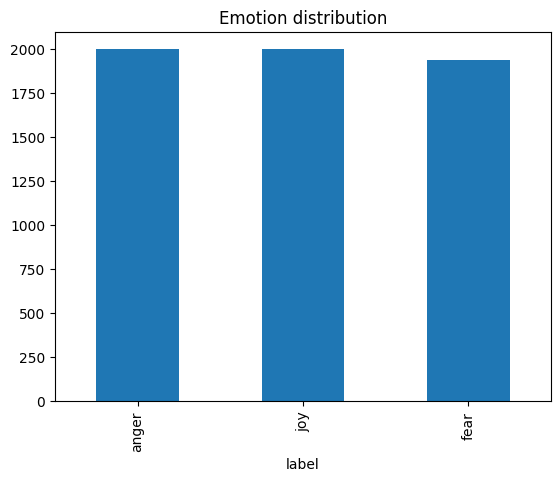

In [3]:
# Auto-detect the text column (longest strings) and the label column (few unique values).
# If detection is wrong for your file, set TEXT_COL / LABEL_COL manually.
obj_cols = df.select_dtypes(include='object').columns
TEXT_COL  = max(obj_cols, key=lambda c: df[c].astype(str).str.len().mean())
LABEL_COL = min([c for c in df.columns if c != TEXT_COL], key=lambda c: df[c].nunique())
print('Text column :', TEXT_COL); print('Label column:', LABEL_COL)
df = df[[TEXT_COL, LABEL_COL]].rename(columns={TEXT_COL:'text', LABEL_COL:'label'})
print(df.isna().sum()); print('Duplicates:', df.duplicated().sum())
df = df.dropna().drop_duplicates().reset_index(drop=True)
df['label'] = df['label'].astype(str).str.strip().str.lower()
print(df['label'].value_counts())
df['label'].value_counts().plot(kind='bar', title='Emotion distribution'); plt.show()

In [4]:
stop_words = set(stopwords.words('english'))
# Keep negations: they flip emotional meaning ("not happy")
stop_words -= {'no','not','nor','never',"don't","didn't","isn't","wasn't"}
lemmatizer = WordNetLemmatizer()

def preprocess(text):
    text = str(text).lower()                                  # 1. lowercase
    text = re.sub(r'http\S+|www\.\S+', ' ', text)             # 2. remove URLs
    text = re.sub(r'@\w+|#', ' ', text)                       # 3. remove mentions / hash symbol
    text = re.sub(r"[^a-z\s']", ' ', text)                    # 4. remove digits/punctuation/emojis
    tokens = word_tokenize(text)                               # 5. tokenization
    tokens = [t for t in tokens if t not in stop_words and len(t) > 1]  # 6. stopword removal
    tokens = [lemmatizer.lemmatize(t) for t in tokens]         # 7. lemmatization
    return ' '.join(tokens)

df['clean_text'] = df['text'].apply(preprocess)
df[['text','clean_text','label']].head()

,text,clean_text,label
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...,fear
1,im so full of life i feel appalled,im full life feel appalled,anger
2,i sit here to write i start to dig out my feel...,sit write start dig feeling think afraid accep...,fear
3,ive been really angry with r and i feel like a...,ive really angry feel like idiot trusting firs...,joy
4,i feel suspicious if there is no one outside l...,feel suspicious no one outside like rapture ha...,fear


## 2. Feature Extraction

In [5]:
df = df[df['clean_text'].str.strip() != ''].reset_index(drop=True)
X_train, X_test, y_train, y_test = train_test_split(
    df['clean_text'], df['label'], test_size=0.2, stratify=df['label'], random_state=RANDOM_STATE)

tfidf = TfidfVectorizer(ngram_range=(1,2), max_features=20000, min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)   # fit ONLY on train to avoid leakage
X_test_tfidf  = tfidf.transform(X_test)
print('Train matrix:', X_train_tfidf.shape, '| Test matrix:', X_test_tfidf.shape)
print(list(tfidf.get_feature_names_out()[:15]))

Train matrix: (4749, 5718) | Test matrix: (1188, 5718)
['aa', 'abandon', 'abandoned', 'abc', 'ability', 'abit', 'able', 'able call', 'able find', 'able help', 'able share', 'absolutely', 'absolutely terrified', 'accept', 'acceptable']


## 3. Model Development

In [6]:
nb = MultinomialNB(alpha=0.5).fit(X_train_tfidf, y_train)
svm = LinearSVC(C=1.0, class_weight='balanced', random_state=RANDOM_STATE).fit(X_train_tfidf, y_train)
pred_nb, pred_svm = nb.predict(X_test_tfidf), svm.predict(X_test_tfidf)

## 4. Model Comparison

===== Naive Bayes =====
              precision    recall  f1-score   support

       anger       0.90      0.91      0.90       400
        fear       0.90      0.91      0.91       388
         joy       0.92      0.90      0.91       400

    accuracy                           0.91      1188
   macro avg       0.91      0.91      0.91      1188
weighted avg       0.91      0.91      0.91      1188

===== SVM =====
              precision    recall  f1-score   support

       anger       0.93      0.94      0.94       400
        fear       0.94      0.93      0.94       388
         joy       0.95      0.95      0.95       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



,Accuracy,Macro F1,Weighted F1
Naive Bayes,0.9057,0.9057,0.9057
SVM,0.9402,0.9402,0.9402


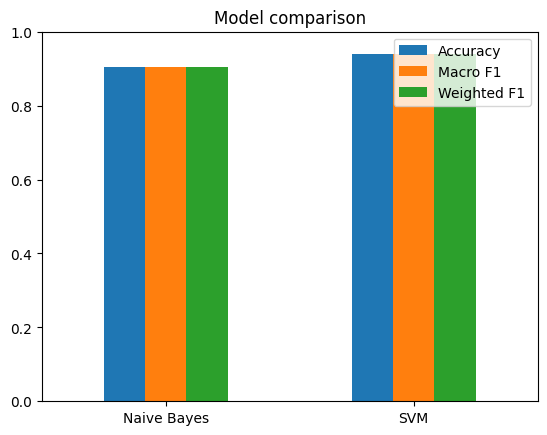

In [7]:
results = {}
for name, pred in [('Naive Bayes', pred_nb), ('SVM', pred_svm)]:
    results[name] = {'Accuracy': accuracy_score(y_test, pred),
                     'Macro F1': f1_score(y_test, pred, average='macro'),
                     'Weighted F1': f1_score(y_test, pred, average='weighted')}
    print(f'===== {name} ====='); print(classification_report(y_test, pred, zero_division=0))
res = pd.DataFrame(results).T.round(4); display(res)
res.plot(kind='bar', ylim=(0,1), title='Model comparison'); plt.xticks(rotation=0); plt.show()

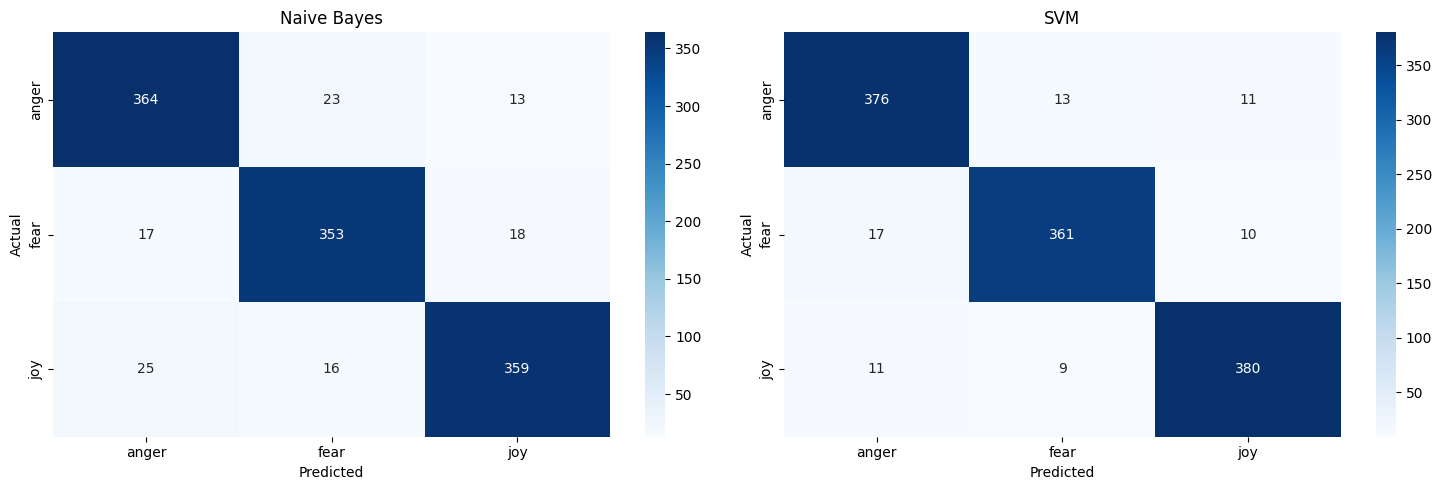

In [8]:
fig, ax = plt.subplots(1,2, figsize=(15,5))
labels = sorted(df['label'].unique())
for a,(n,p) in zip(ax, [('Naive Bayes',pred_nb),('SVM',pred_svm)]):
    sns.heatmap(confusion_matrix(y_test,p,labels=labels), annot=True, fmt='d', cmap='Blues',
                xticklabels=labels, yticklabels=labels, ax=a); a.set_title(n)
    a.set_xlabel('Predicted'); a.set_ylabel('Actual')
plt.tight_layout(); plt.show()

## 5. Impact of Preprocessing

In [9]:
# Same SVM on raw (uncleaned) text vs cleaned text
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(df['text'], df['label'], test_size=0.2,
                                              stratify=df['label'], random_state=RANDOM_STATE)
raw_vec = TfidfVectorizer(ngram_range=(1,2), max_features=20000, min_df=2, sublinear_tf=True)
raw_svm = LinearSVC(class_weight='balanced', random_state=RANDOM_STATE).fit(raw_vec.fit_transform(Xr_tr), yr_tr)
raw_pred = raw_svm.predict(raw_vec.transform(Xr_te))
print('SVM raw text    -> Acc %.4f | Macro F1 %.4f' % (accuracy_score(yr_te, raw_pred), f1_score(yr_te, raw_pred, average='macro')))
print('SVM cleaned text-> Acc %.4f | Macro F1 %.4f' % (accuracy_score(y_test, pred_svm), f1_score(y_test, pred_svm, average='macro')))

SVM raw text    -> Acc 0.9192 | Macro F1 0.9192
SVM cleaned text-> Acc 0.9402 | Macro F1 0.9402


In [10]:
# Quick sanity check on new sentences
samples = ["I am so excited and thrilled about the trip!", "I can't stop crying, I miss him so much", "This makes me furious"]
for s in samples:
    v = tfidf.transform([preprocess(s)])
    print(f'{s!r} -> NB: {nb.predict(v)[0]} | SVM: {svm.predict(v)[0]}')

'I am so excited and thrilled about the trip!' -> NB: joy | SVM: joy
"I can't stop crying, I miss him so much" -> NB: fear | SVM: fear
'This makes me furious' -> NB: anger | SVM: anger


## 6. Conclusion: chosen model and suitability
**Chosen model: Linear SVM** (accuracy 94.0%, macro F1 0.94).

**Why it suits emotion classification**
- Text features are high-dimensional and sparse (thousands of TF-IDF terms), and linear SVMs excel there.
- Emotions are largely separable by distinctive keywords and short phrases (*terrified*, *furious*, *delighted*), which a linear boundary captures well.
- Margin maximisation gives robust generalisation, with strong recall and precision across all classes.
- Naive Bayes is still a good, much faster baseline (90.6%), but its independence assumption ignores word interactions and context, which costs accuracy.

**Limitations**
- Bag-of-words ignores word order, sarcasm and context. For example, *"I can't stop crying, I miss him so much"* was predicted as fear, because the dataset has only anger, fear and joy and no sadness class.
- Some labels look noisy (e.g. an "angry" comment labelled joy), which caps achievable accuracy.
- Future work: hyper-parameter tuning with cross-validation, and transformer models (BERT) for context-aware features.